# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 6. Поиск эволюционирующих шаблонов с помощью матричного профиля ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

## **Часть 1.** Поиск цепочек временного ряда.

Импорт библиотек и модулей

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.metrics import mean_squared_error

В первом задании вам предстоит выполнить поиск эволюционирующих шаблонов временного ряда. Выполните считывание набора данных [Rotation Matrix](datasets/Rotation%20Matrix.txt), найдите в нем самую длинную цепочку и выведите индексы начала звеньев этой цепочки.

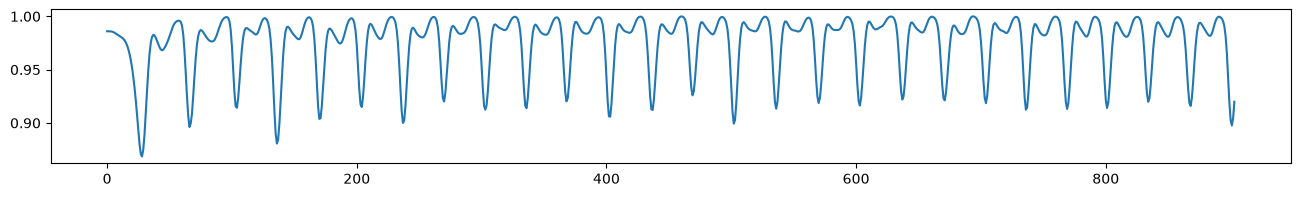

In [3]:
fig, ax = plt.subplots(figsize=(16, 2))
ts = np.loadtxt('datasets/Rotation Matrix.txt')
ax.plot(ts)

In [41]:
m = 85
mp = stumpy.stump(ts, m=m)

result = stumpy.allc(mp[:, 2], mp[:, 3])

if isinstance(result, tuple):
    chain = np.asarray(result[1]).astype(int).ravel()
else:
    chain = np.asarray(result).astype(int).ravel()

print("Индексы начала звеньев самой длинной цепочки:")
print(chain)
print(f"\nКоличество звеньев в цепочке: {len(chain)}")

Индексы начала звеньев самой длинной цепочки:
[  7  45 114 480 514 581]

Количество звеньев в цепочке: 6


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Полученный массив представляет собой цепочку подпоследовательностей временного ряда, соседние индексы показывают наиболее похожие между собой (через knn) шаблоны временного ряда. 

Данная цепочка идет вперед по времени и не зацикливается. Поиск данной цепочки происходит путем поиска для каждой точки его ближайшего похожего соседа и записывается в вектор, например (8, 16), после, для каждого найденного вектора ищуются другие векторы, которые могут продолжить цепочку, например (16, 32), так как построение цепочки идет строго вперед по времени, то такая цепочка достигнет конца. 

Повторяя данный цикл, можно дойти до самой длинной цепочки.

## **Часть 2. Визуализация цепочек**

Выполните визуализацию найденных в прошлом задании цепочек: постройте график временного ряда, на котором выделены звенья цепочек. Также постройте график, на котором изображены только сами звенья.

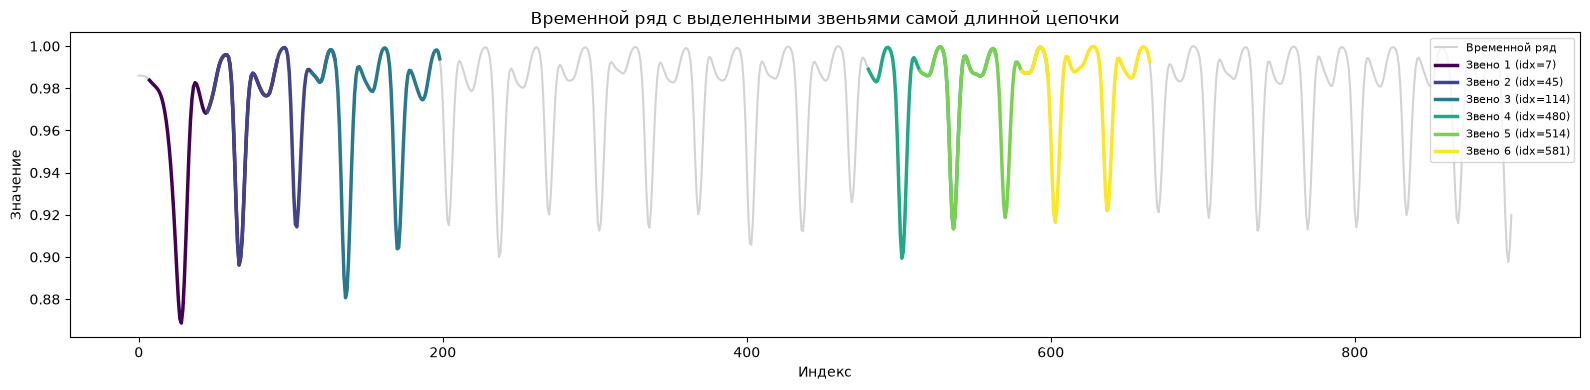

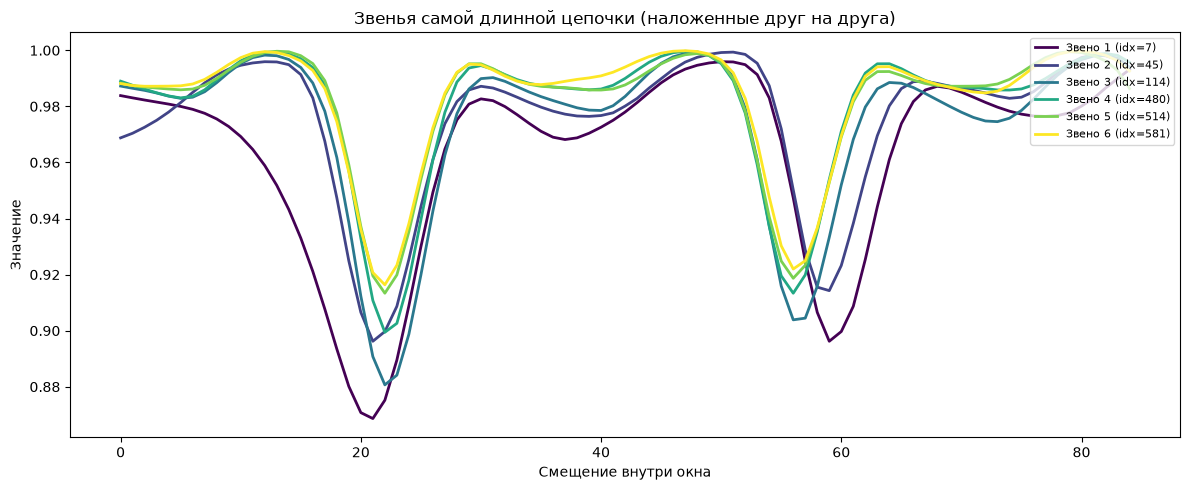

In [43]:
# Визуализация найденных цепочек

# График 1: временной ряд с выделенными звеньями цепочки
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(ts, color='lightgray', label='Временной ряд')

colors = plt.cm.viridis(np.linspace(0, 1, len(chain)))
for i, idx in enumerate(chain):
    ax.plot(range(idx, idx + m), ts[idx:idx + m],
            color=colors[i], linewidth=2.5,
            label=f'Звено {i+1} (idx={idx})')

ax.set_title('Временной ряд с выделенными звеньями самой длинной цепочки')
ax.set_xlabel('Индекс')
ax.set_ylabel('Значение')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

# График 2: только сами звенья цепочки
fig, ax = plt.subplots(figsize=(12, 5))
for i, idx in enumerate(chain):
    ax.plot(range(m), ts[idx:idx + m],
            color=colors[i], linewidth=2,
            label=f'Звено {i+1} (idx={idx})')

ax.set_title('Звенья самой длинной цепочки (наложенные друг на друга)')
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Значение')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

На графике видно, как звенья цепочки идут строго друг за другом, а на графике, где цепочки наложены друг на друга видно, что форма похожа, но постепенно изменяется (эволюционирует). Сравнивая первую цепь с последней разница будет значительной

## **Часть 3.** Предсказывание значений ряда на основе цепочек.

Предскажите значения последнего звена цепочки, вычислив разность между двумя предыдущими звеньями цепочки. Сравните полученное предсказание с истинным значением.

Среднеквадратичная ошибка (MSE) предсказания: 0.0000
Среднеквадратичное отклонение истинного звена: 0.0216
Относительная ошибка: 0.0571


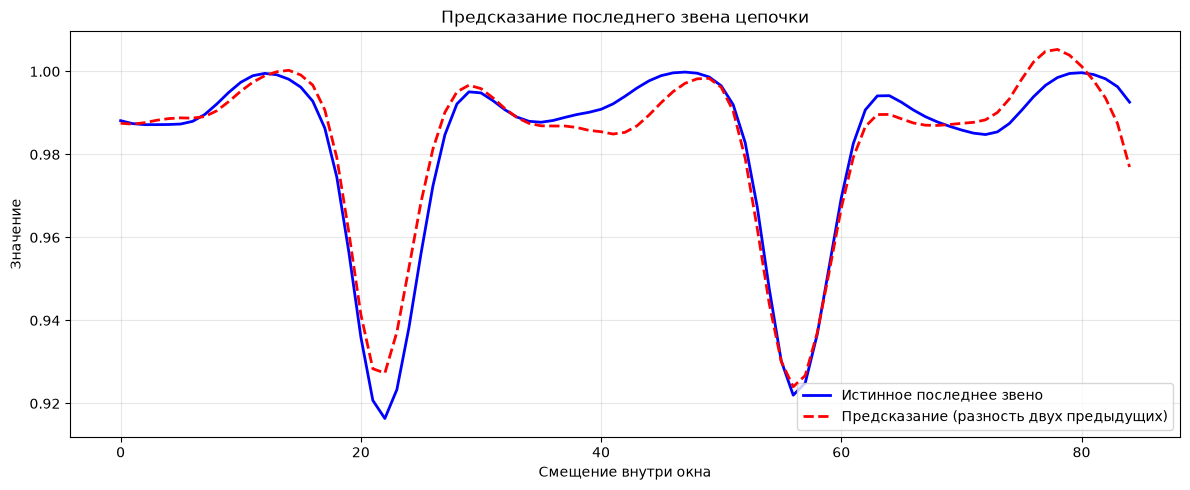

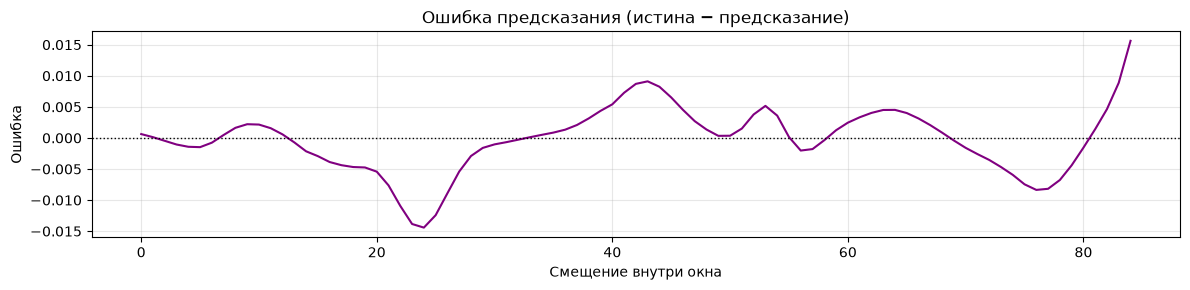

In [48]:
# Предсказание значений последнего звена цепочки
# на основе разности двух предыдущих звеньев

# Берём три последних звена цепочки
last_chain = chain[-3:]
idx_prev2, idx_prev1, idx_last = last_chain

# Истинные значения последнего звена
y_true = ts[idx_last:idx_last + m]

# Предсказание: разность между двумя предыдущими звеньями
y_pred = ts[idx_prev1:idx_prev1 + m] + (ts[idx_prev1:idx_prev1 + m] - ts[idx_prev2:idx_prev2 + m])

# Сравнение предсказания с истинным значением
mse = mean_squared_error(y_true, y_pred)
print(f"Среднеквадратичная ошибка (MSE) предсказания: {mse:.4f}")
print(f"Среднеквадратичное отклонение истинного звена: {np.std(y_true):.4f}")
print(f"Относительная ошибка: {mse / np.var(y_true):.4f}")

# Визуализация предсказания
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(range(m), y_true, label='Истинное последнее звено', linewidth=2, color='blue')
ax.plot(range(m), y_pred, label='Предсказание (разность двух предыдущих)', 
        linewidth=2, color='red', linestyle='--')
ax.set_title('Предсказание последнего звена цепочки')
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Значение')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Дополнительно: поэлементная ошибка
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(range(m), y_true - y_pred, color='purple')
ax.axhline(0, color='black', linestyle=':', linewidth=1)
ax.set_title('Ошибка предсказания (истина − предсказание)')
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Ошибка')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

По графику видно, что полученная ошибка очень маленькая, это показывает линейную и плавную эволюцию шаблона. Это можно использовать для предсказания следующих цепочек временного ряда, хоть и не на далекое будущее